# 10 · Pick the best saved epoch

Ultralytics keeps `best.pt` by its own fitness (mostly mask mAP), which isn't what the app needs. This notebook scores **every saved epoch** of a run (`weights/epoch*.pt`, plus `best.pt` and `last.pt`) by **coverage accuracy on the validation split**, with the same score J as `09_tune_inference.ipynb`:
- J = mean over the two diseases of (coverage MAE on infected images ÷ the same MAE for `best.pt`), so J < 1 beats `best.pt`;
- an epoch may not lose more than 0.02 presence F1 on either disease.

The winner is then checked once on the test split against `best.pt` (paired bootstrap, 95 % CI).
To keep more epochs, set `SAVE_PERIOD` in `02_train` (5 = every 5 epochs).

In [1]:
import csv
import json
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from dotenv import load_dotenv
from pycocotools.coco import COCO
from ultralytics import YOLO

from eval_utils import CLASSES, DISEASES, paint_class_map

ROOT = Path.cwd()
load_dotenv(ROOT / ".env")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

C:\Users\bp67339\PCPL\plant disease detection\training\training_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

- `RUN`: the run folder to search.
- `VALID_DATA` / `TEST_DATA`: COCO dataset folders. Validation selects; test checks once. Use the dataset the run was trained on for validation, and the fixed test set (e.g. `lds_test-v1-coco`) for test.
- `THRESHOLDS`: the confidence thresholds used for scoring, e.g. the tuned ones from 09.

In [2]:
RUN = ROOT / "runs" / "yolo26x-seg_data-v2"
VALID_DATA = ROOT / "datasets" / "lds_v1-v2-coco"
TEST_DATA = ROOT / "datasets" / "lds_v1-v2-coco"
THRESHOLDS = {"leaf": 0.2, "leaf_spot": 0.25, "powdery_mildew": 0.3}
IMGSZ, IOU = 1024, 0.7
F1_DROP = 0.02
N_BOOT, SEED = 1000, 0

OUT = ROOT / "results" / f"checkpoints_{RUN.name}"
OUT.mkdir(parents=True, exist_ok=True)
weights = RUN / "weights"
epoch_files = sorted(weights.glob("epoch*.pt"), key=lambda p: int(re.findall(r"\d+", p.stem)[0]))
CANDIDATES = {"best.pt": weights / "best.pt", "last.pt": weights / "last.pt",
              **{p.stem: p for p in epoch_files}}
print(len(CANDIDATES), "checkpoints:", ", ".join(CANDIDATES))

11 checkpoints: best.pt, last.pt, epoch0, epoch10, epoch20, epoch30, epoch40, epoch50, epoch60, epoch70, epoch80


In [3]:
def load_split(data_dir, split):
    coco = COCO(str(data_dir / split / "_annotations.coco.json"))
    names = {c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())}
    items = []
    for img in coco.loadImgs(coco.getImgIds()):
        anns = coco.loadAnns(coco.getAnnIds(imgIds=img["id"]))
        gt = paint_class_map([coco.annToMask(a).astype(bool) for a in anns], [names[a["category_id"]] for a in anns],
                             (img["height"], img["width"]))
        items.append((data_dir / split / img["file_name"], gt))
    return items


ORDER = (("leaf", CLASSES.index("leaf")), ("powdery_mildew", CLASSES.index("powdery_mildew")),
         ("leaf_spot", CLASSES.index("leaf_spot")))  # paint order: leaves first, spots win over mildew


def confusions(ckpt, items):
    # One 4×4 pixel confusion per image at THRESHOLDS
    model = YOLO(ckpt)
    out = np.zeros((len(items), 4, 4), np.int64)
    for k, (path, gt) in enumerate(items):
        r = model.predict(str(path), imgsz=IMGSZ, iou=IOU, conf=0.01, retina_masks=True, verbose=False, device=0)[0]
        gt_t = torch.as_tensor(gt, device=DEVICE).long()
        pmap = torch.zeros_like(gt_t)
        if r.masks is not None:
            masks, conf = r.masks.data.bool(), r.boxes.conf
            names = [r.names[int(c)] for c in r.boxes.cls]
            for name, cls_id in ORDER:
                sel = torch.tensor([n == name for n in names], device=masks.device) & (conf >= THRESHOLDS[name])
                if sel.any():
                    pmap[masks[sel].any(0)] = cls_id
        out[k] = torch.bincount((gt_t * 4 + pmap).ravel(), minlength=16).reshape(4, 4).cpu().numpy()
    del model
    torch.cuda.empty_cache()
    return out


def metrics(C):
    total = C.sum(0).astype(float)
    tp = np.diag(total)
    fp, fn = total.sum(0) - tp, total.sum(1) - tp
    out = {"pixel": {c: tp[i] / (tp[i] + fp[i] + fn[i]) if tp[i] + fp[i] + fn[i] else np.nan
                     for i, c in enumerate(CLASSES) if i}}
    gt_leaf, pr_leaf = C[:, 1:, :].sum((1, 2)), C[:, :, 1:].sum((1, 2))
    ok = (gt_leaf > 0) & (pr_leaf > 0)
    for d in DISEASES:
        i = CLASSES.index(d)
        g, p = 100 * C[ok, i, :].sum(1) / gt_leaf[ok], 100 * C[ok, :, i].sum(1) / pr_leaf[ok]
        has_g, has_p = g > 0, p > 0
        tp_i, fp_i, fn_i = (has_g & has_p).sum(), (~has_g & has_p).sum(), (has_g & ~has_p).sum()
        prec = tp_i / (tp_i + fp_i) if tp_i + fp_i else np.nan
        rec = tp_i / (tp_i + fn_i) if tp_i + fn_i else np.nan
        err = p - g
        out[d] = {"mae_pos": np.abs(err[has_g]).mean() if has_g.any() else np.nan,
                  "bias_pos": err[has_g].mean() if has_g.any() else np.nan,
                  "presence_f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0}
    return out

## Score every checkpoint on validation

In [4]:
valid = load_split(VALID_DATA, "valid")
print(len(valid), "validation images")
scores = {}
for name, ckpt in CANDIDATES.items():
    scores[name] = metrics(confusions(ckpt, valid))
    m = scores[name]
    print(f"{name:<9} spot MAE+ {m['leaf_spot']['mae_pos']:.3f} bias {m['leaf_spot']['bias_pos']:+.3f} | "
          f"mildew MAE+ {m['powdery_mildew']['mae_pos']:.3f} bias {m['powdery_mildew']['bias_pos']:+.3f} | "
          f"IoU leaf {m['pixel']['leaf']:.3f} spot {m['pixel']['leaf_spot']:.3f} mildew {m['pixel']['powdery_mildew']:.3f}", flush=True)

base = scores["best.pt"]
rows = []
for name, m in scores.items():
    J = float(np.mean([m[d]["mae_pos"] / base[d]["mae_pos"] for d in DISEASES]))
    allowed = all(m[d]["presence_f1"] >= base[d]["presence_f1"] - F1_DROP for d in DISEASES)
    rows.append({"checkpoint": name, "J": J, "allowed": allowed,
                 **{f"{d}_{k}": m[d][k] for d in DISEASES for k in ("mae_pos", "bias_pos", "presence_f1")},
                 **{f"iou_{c}": v for c, v in m["pixel"].items()}})
WINNER = min((r for r in rows if r["allowed"]), key=lambda r: r["J"])["checkpoint"]
with open(OUT / "valid_scores.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
print(f"\nwinner on validation: {WINNER} (J {next(r['J'] for r in rows if r['checkpoint'] == WINNER):.3f}; best.pt = 1.000)")

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!


146 validation images


best.pt   spot MAE+ 0.401 bias +0.012 | mildew MAE+ 0.730 bias -0.031 | IoU leaf 0.881 spot 0.660 mildew 0.526


last.pt   spot MAE+ 0.429 bias +0.061 | mildew MAE+ 0.789 bias +0.040 | IoU leaf 0.881 spot 0.656 mildew 0.538


epoch0    spot MAE+ 0.718 bias -0.468 | mildew MAE+ 1.433 bias -1.002 | IoU leaf 0.810 spot 0.566 mildew 0.384


epoch10   spot MAE+ 0.455 bias -0.184 | mildew MAE+ 1.041 bias -0.523 | IoU leaf 0.853 spot 0.640 mildew 0.466


... (4 outputs left out)

epoch60   spot MAE+ 0.404 bias +0.095 | mildew MAE+ 0.772 bias -0.180 | IoU leaf 0.879 spot 0.656 mildew 0.545


epoch70   spot MAE+ 0.422 bias +0.032 | mildew MAE+ 0.833 bias +0.048 | IoU leaf 0.879 spot 0.657 mildew 0.553


epoch80   spot MAE+ 0.399 bias +0.059 | mildew MAE+ 0.778 bias +0.006 | IoU leaf 0.880 spot 0.663 mildew 0.543



winner on validation: best.pt (J 1.000; best.pt = 1.000)


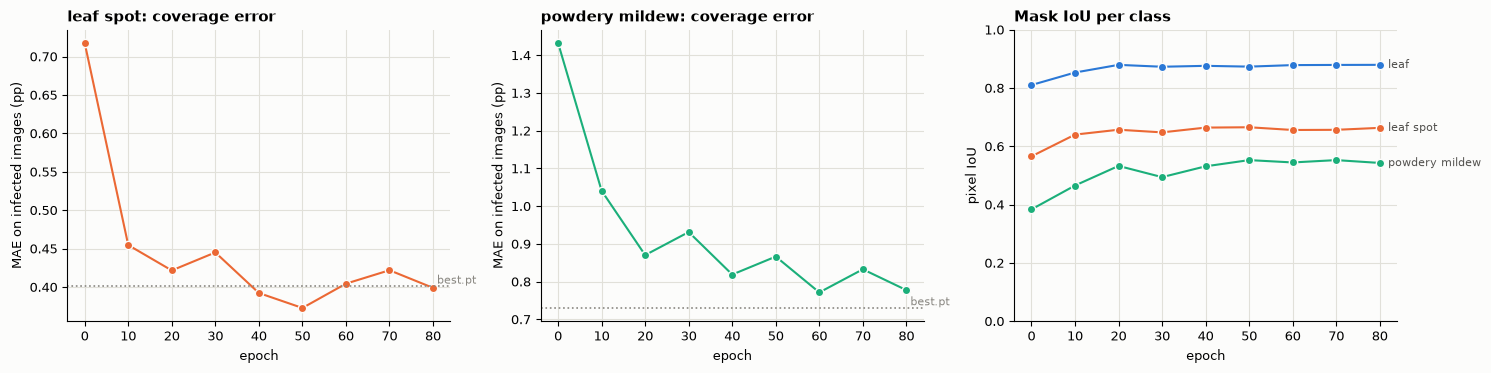

In [5]:
SURFACE, INK2, MUTED, GRID = "#fcfcfb", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9, "savefig.bbox": "tight"})
ep = [(int(re.findall(r"\d+", n)[0]), n) for n in scores if n.startswith("epoch")]
ep.sort()
if ep:
    xs = [e for e, _ in ep]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, d, color in ((axes[0], "leaf_spot", "#eb6834"), (axes[1], "powdery_mildew", "#1baf7a")):
        ax.plot(xs, [scores[n][d]["mae_pos"] for _, n in ep], marker="o", color=color, markeredgecolor=SURFACE)
        ax.axhline(base[d]["mae_pos"], color=MUTED, linestyle=":", linewidth=1.2)
        ax.text(xs[-1], base[d]["mae_pos"], " best.pt", color=MUTED, va="bottom", fontsize=8)
        ax.set(xlabel="epoch", ylabel="MAE on infected images (pp)", title=f"{d.replace('_', ' ')}: coverage error")
    for c, color in (("leaf", "#2a78d6"), ("leaf_spot", "#eb6834"), ("powdery_mildew", "#1baf7a")):
        ys = [scores[n]["pixel"][c] for _, n in ep]
        axes[2].plot(xs, ys, marker="o", color=color, markeredgecolor=SURFACE)
        axes[2].annotate(c.replace("_", " "), (xs[-1], ys[-1]), xytext=(6, 0), textcoords="offset points",
                         va="center", color=INK2, fontsize=8, annotation_clip=False)
    axes[2].set(xlabel="epoch", ylabel="pixel IoU", ylim=(0, 1), title="Mask IoU per class")
    fig.tight_layout()
    fig.savefig(OUT / "epochs.png", dpi=150)
    plt.show()

## One check on the test split: winner vs best.pt

In [6]:
if WINNER == "best.pt":
    print("best.pt is already the best checkpoint on validation; nothing to compare")
else:
    test = load_split(TEST_DATA, "test")
    C = {n: confusions(CANDIDATES[n], test) for n in ("best.pt", WINNER)}
    rng = np.random.default_rng(SEED)
    boots = [rng.integers(0, len(test), len(test)) for _ in range(N_BOOT)]
    result = {}
    for d in DISEASES:
        for k in ("mae_pos", "bias_pos"):
            a, b = metrics(C["best.pt"])[d][k], metrics(C[WINNER])[d][k]
            diff = np.array([metrics(C[WINNER][i])[d][k] - metrics(C["best.pt"][i])[d][k] for i in boots])
            lo, hi = np.nanpercentile(diff, [2.5, 97.5])
            result[f"{d} {k}"] = {"best.pt": float(a), WINNER: float(b), "diff_ci95": [float(lo), float(hi)]}
            print(f"{d:<15} {k:<9} best.pt {a:.3f} | {WINNER} {b:.3f} | diff {b - a:+.3f} [{lo:+.3f}, {hi:+.3f}]")
    (OUT / "test_check.json").write_text(json.dumps({"winner": WINNER, "thresholds": THRESHOLDS, "test": result}, indent=1))
    print(f"\nUse {CANDIDATES[WINNER].relative_to(ROOT)} only if the MAE differences are negative and their CIs exclude 0.")

best.pt is already the best checkpoint on validation; nothing to compare
